# CIE 2 – Activity 2: Binary Classification

**Course:** Regression and Classification Algorithms  
**Activity:** Binary Classification Activity  
**Dataset:** Breast Cancer Wisconsin (Diagnostic) dataset  
**Student:** Manas Giri  
**Roll Number:** AD3159  
**College:** Zeal College of Engineering and Research, Narhe, Pune

## 1. Problem statement

The aim is to build a binary classification model that predicts whether a breast tumour sample is **malignant** or **benign** using numerical measurements. We use Logistic Regression, evaluate the model with a confusion matrix and classification metrics, study the ROC curve and ROC-AUC, compare decision thresholds, and make one new prediction.

**Responsible-use note:** This is an educational dataset and model only. It is not a medical diagnostic tool and must not be used for real clinical decisions.

## 2. Dataset description and source

The Breast Cancer Wisconsin (Diagnostic) dataset contains **569 observations**, **30 numerical input features**, and a binary target with two classes:
- **Malignant** – class 0
- **Benign** – class 1

The measurements are computed from digitized images of fine needle aspirate (FNA) samples. Features describe characteristics of cell nuclei, such as radius, texture, perimeter, area and smoothness.

- UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
- Scikit-learn documentation: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html

The included CSV is exported from Scikit-learn's copy of this public dataset. The target names in Scikit-learn are `0 = malignant` and `1 = benign`.

## 3. Import libraries and load the dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, classification_report
)

RANDOM_STATE = 42

cancer = load_breast_cancer(as_frame=True)
df = cancer.frame.copy()

# Convert the target to a readable binary label:
# 1 = malignant (positive class), 0 = benign (negative class)
df["target"] = (df["target"] == 0).astype(int)

print("Dataset shape:", df.shape)
print("Number of observations:", df.shape[0])
print("Number of numerical input features:", df.shape[1] - 1)
print("Target classes: 0 = benign, 1 = malignant")
display(df.head())

Dataset shape: (569, 31)
Number of observations: 569
Number of numerical input features: 30
Target classes: 0 = benign, 1 = malignant


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 4. Inspect and understand the data

In [2]:
print("Data types:")
display(df.dtypes.to_frame("Data type"))

print("Summary statistics:")
display(df.describe().T)

print("Missing values:")
display(df.isnull().sum().to_frame("Missing values"))

print("Duplicate rows:", df.duplicated().sum())

print("Class counts:")
display(df["target"].value_counts().rename(index={0: "Benign (0)", 1: "Malignant (1)"}).to_frame("Count"))

Data types:


,Data type
mean radius,float64
mean texture,float64
mean perimeter,float64
mean area,float64
mean smoothness,float64
mean compactness,float64
mean concavity,float64
mean concave points,float64
mean symmetry,float64
mean fractal dimension,float64


Summary statistics:


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


Missing values:


,Missing values
mean radius,0
mean texture,0
mean perimeter,0
mean area,0
mean smoothness,0
mean compactness,0
mean concavity,0
mean concave points,0
mean symmetry,0
mean fractal dimension,0


Duplicate rows: 0
Class counts:


,Count
target,
Benign (0),357
Malignant (1),212


### Data preparation decisions

The target is converted so malignant is the positive class (1), making recall and precision easier to interpret for identifying malignant samples. The notebook checks missing values and duplicates before training. If missing values are absent, no imputation is needed. We use a stratified train-test split to preserve the class proportions in both sets. Standardisation is fitted inside a Pipeline using training data only, preventing test-data leakage.

## 5. Explore the class distribution and selected features

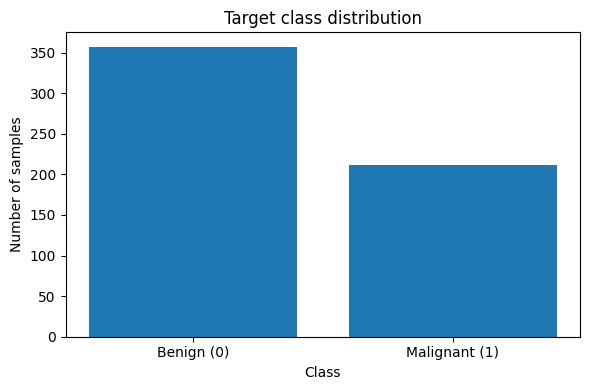

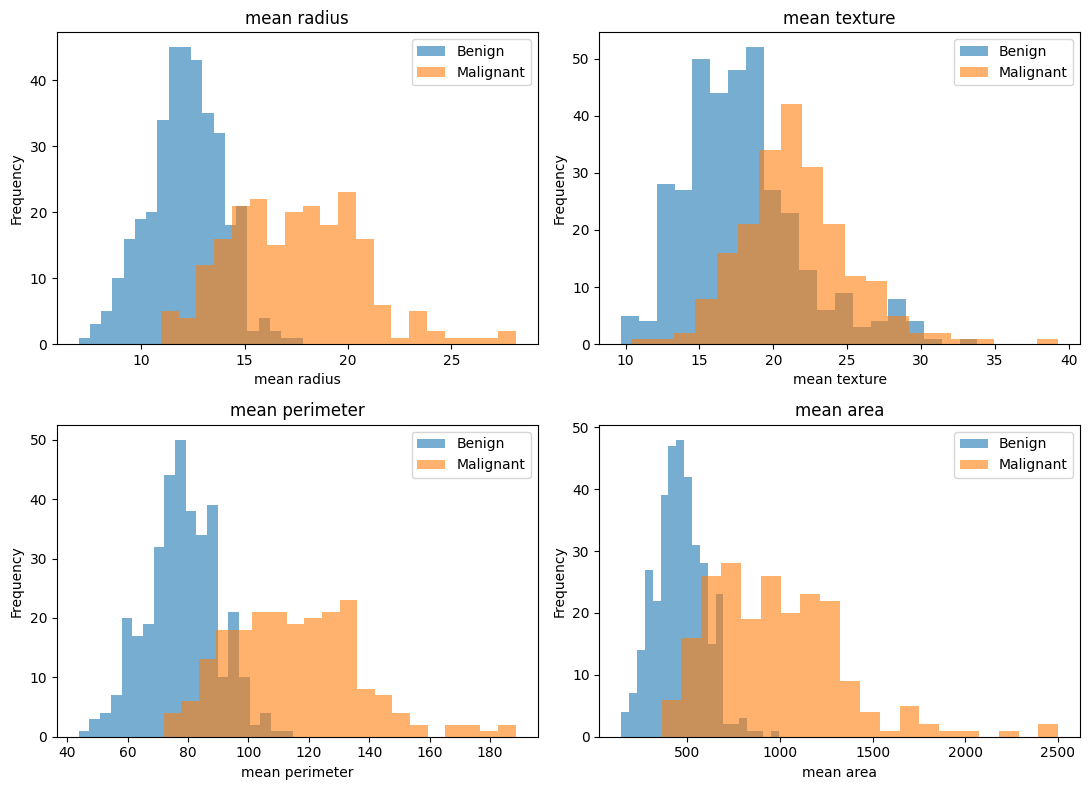

In [3]:
class_counts = df["target"].value_counts().sort_index()
class_labels = ["Benign (0)", "Malignant (1)"]

plt.figure(figsize=(6, 4))
plt.bar(class_labels, [class_counts.get(0, 0), class_counts.get(1, 0)])
plt.title("Target class distribution")
plt.xlabel("Class")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.show()

selected_for_plot = ["mean radius", "mean texture", "mean perimeter", "mean area"]
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, feature in zip(axes.ravel(), selected_for_plot):
    ax.hist(df.loc[df.target == 0, feature], bins=20, alpha=0.6, label="Benign")
    ax.hist(df.loc[df.target == 1, feature], bins=20, alpha=0.6, label="Malignant")
    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")
    ax.legend()
plt.tight_layout()
plt.show()

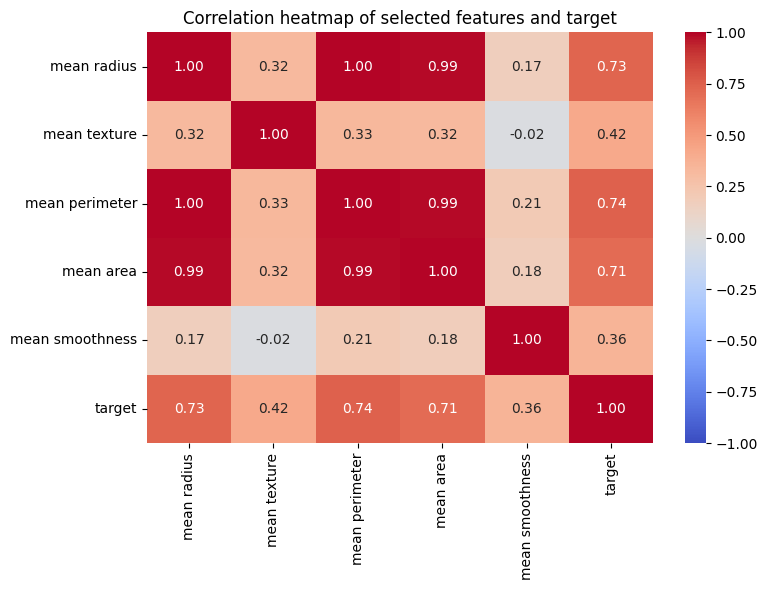

In [4]:
# Correlation heatmap for a small set of interpretable features and target
heatmap_features = ["mean radius", "mean texture", "mean perimeter", "mean area", "mean smoothness", "target"]
corr = df[heatmap_features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation heatmap of selected features and target")
plt.tight_layout()
plt.show()

### Exploration observations

The class distribution shows how many benign and malignant examples are available. The histograms compare selected feature distributions between the two classes. The heatmap shows pairwise linear correlations; high correlation between predictors can indicate overlapping information, but correlation alone does not prove causation.

## 6. Split the data into training and testing sets

In [5]:
X = df.drop(columns="target")
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training class proportions:")
display(y_train.value_counts(normalize=True).rename(index={0: "Benign", 1: "Malignant"}).to_frame("Proportion"))
print("Testing class proportions:")
display(y_test.value_counts(normalize=True).rename(index={0: "Benign", 1: "Malignant"}).to_frame("Proportion"))

Training observations: 455
Testing observations: 114
Training class proportions:


,Proportion
target,
Benign,0.626374
Malignant,0.373626


Testing class proportions:


,Proportion
target,
Benign,0.631579
Malignant,0.368421


We use 80% of the data for training and 20% for testing. `stratify=y` keeps approximately the same proportion of benign and malignant samples in both sets. The random state is fixed at 42 so the experiment can be reproduced.

## 7. Train Logistic Regression

In [6]:
# StandardScaler and LogisticRegression are placed in one Pipeline.
# The scaler learns its means and standard deviations from training data only.
model = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("logistic_regression", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
])

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")
print("Training accuracy:", round(model.score(X_train, y_train), 4))

Logistic Regression model trained successfully.
Training accuracy: 0.9868


### Why standardisation?

The 30 numerical features have different scales. StandardScaler transforms each feature to a comparable scale using the training-set mean and standard deviation. This helps Logistic Regression optimise its coefficients. Putting scaling inside the Pipeline ensures the test data does not influence the scaling parameters.

## 8. Predict the test set and create a confusion matrix

Confusion matrix (rows = actual, columns = predicted):


,Predicted benign (0),Predicted malignant (1)
Actual benign (0),71,1
Actual malignant (1),3,39


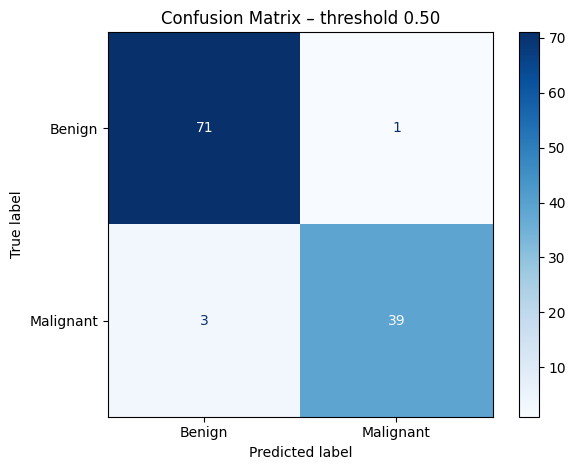

In [7]:
# Probability of the positive class (malignant = 1)
y_probability = model.predict_proba(X_test)[:, 1]

# Default decision threshold is 0.50
default_threshold = 0.50
y_pred = (y_probability >= default_threshold).astype(int)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print("Confusion matrix (rows = actual, columns = predicted):")
display(pd.DataFrame(
    cm,
    index=["Actual benign (0)", "Actual malignant (1)"],
    columns=["Predicted benign (0)", "Predicted malignant (1)"]
))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Benign", "Malignant"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix – threshold 0.50")
plt.tight_layout()
plt.show()

### Confusion matrix terms

- **True Negative (TN):** benign sample correctly predicted as benign.
- **False Positive (FP):** benign sample incorrectly predicted as malignant.
- **False Negative (FN):** malignant sample incorrectly predicted as benign.
- **True Positive (TP):** malignant sample correctly predicted as malignant.

For this activity, malignant is the positive class. A false negative means a malignant sample was missed by the model.

## 9. Calculate classification metrics

In [8]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_probability)

metrics_table = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Score": [accuracy, precision, recall, f1, roc_auc]
})
display(metrics_table.round(4))

print("Classification report:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    zero_division=0
))

,Metric,Score
0,Accuracy,0.9649
1,Precision,0.9750
2,Recall,0.9286
3,F1-score,0.9512
4,ROC-AUC,0.9960


Classification report:
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



### Metric meanings

- **Accuracy:** proportion of all test samples classified correctly.
- **Precision:** among samples predicted malignant, the proportion that are actually malignant.
- **Recall (Sensitivity):** among actual malignant samples, the proportion correctly identified.
- **F1-score:** harmonic mean of precision and recall.
- **ROC-AUC:** measures how well the model ranks positive samples above negative samples across thresholds. A value closer to 1 indicates better ranking performance.

Because missing a malignant sample can be important, recall for the malignant class should be considered carefully alongside precision.

## 10. Plot the ROC curve

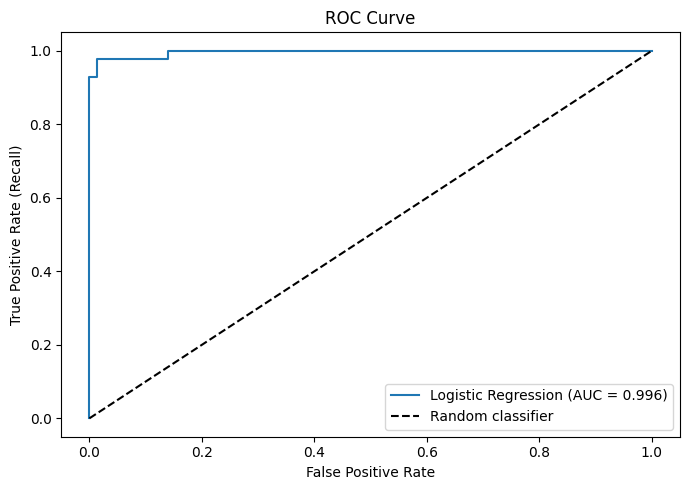

In [9]:
fpr, tpr, thresholds = roc_curve(y_test, y_probability)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()

The ROC curve plots true positive rate against false positive rate at different probability thresholds. The AUC summarises the curve: higher AUC means better ability to separate the two classes over all thresholds.

## 11. Compare decision thresholds: 0.30, 0.50 and 0.70

In [10]:
threshold_rows = []
for threshold in [0.30, 0.50, 0.70]:
    threshold_pred = (y_probability >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, threshold_pred),
        "Precision": precision_score(y_test, threshold_pred, zero_division=0),
        "Recall": recall_score(y_test, threshold_pred, zero_division=0),
        "F1-score": f1_score(y_test, threshold_pred, zero_division=0)
    })

threshold_comparison = pd.DataFrame(threshold_rows)
display(threshold_comparison.round(4))

,Threshold,Accuracy,Precision,Recall,F1-score
0,0.3,0.9825,0.9762,0.9762,0.9762
1,0.5,0.9649,0.9750,0.9286,0.9512
2,0.7,0.9649,1.0000,0.9048,0.9500


### Threshold decision

A lower threshold usually identifies more positive cases, which can increase recall but may also increase false positives and reduce precision. A higher threshold usually predicts fewer positive cases, which can improve precision but may miss more positives. The recommended threshold should reflect the task's priority. For this educational example, we inspect the table and favour a threshold that provides strong malignant-class recall without an excessive loss of precision. The default threshold is 0.50 unless the observed comparison supports another choice.

## 12. Make one new prediction

In [11]:
# Use a real example row from the held-out test set as a new unseen sample.
new_sample = X_test.iloc[[0]]
actual_class = int(y_test.iloc[0])
predicted_probability = model.predict_proba(new_sample)[0, 1]
predicted_class = int(predicted_probability >= default_threshold)

label_map = {0: "Benign", 1: "Malignant"}
print("Input sample: first record from the test set")
print("Predicted probability of malignant:", round(predicted_probability, 4))
print("Predicted class:", label_map[predicted_class])
print("Actual class (for checking):", label_map[actual_class])

Input sample: first record from the test set
Predicted probability of malignant: 0.0004
Predicted class: Benign
Actual class (for checking): Benign


## 13. Important features and model interpretation

In [12]:
logistic = model.named_steps["logistic_regression"]
coefficient_table = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": logistic.coef_[0],
    "Absolute coefficient": np.abs(logistic.coef_[0])
}).sort_values("Absolute coefficient", ascending=False)

display(coefficient_table.head(10).round(4))

,Feature,Coefficient,Absolute coefficient
21,worst texture,1.4341,1.4341
10,radius error,1.2333,1.2333
28,worst symmetry,1.0613,1.0613
7,mean concave points,0.9528,0.9528
26,worst concavity,0.9114,0.9114
13,area error,0.9090,0.9090
15,compactness error,-0.9069,0.9069
23,worst area,0.9005,0.9005
20,worst radius,0.8970,0.8970
6,mean concavity,0.7823,0.7823


The logistic regression coefficient describes how a one-standard-deviation increase in a feature changes the log-odds of the positive class (malignant), while other features are held constant. Positive coefficients increase the model's estimated log-odds of malignant; negative coefficients decrease them. Coefficients are not proof of cause and should be interpreted cautiously when predictors are correlated.

## 14. Decision log

| Decision | Choice | Reason |
|---|---|---|
| Dataset | Breast Cancer Wisconsin (Diagnostic) | Public dataset with 569 rows, numeric features and exactly two classes. |
| Positive class | Malignant = 1 | Makes recall directly measure how many malignant cases are detected. |
| Train/test split | 80:20 with stratification | Evaluates unseen data while preserving class proportions. |
| Preprocessing | StandardScaler in a Pipeline | Features have different scales; pipeline avoids fitting the scaler on test data. |
| Model | Logistic Regression | Suitable baseline for binary classification and provides class probabilities. |
| Thresholds | 0.30, 0.50 and 0.70 | Shows how the precision-recall trade-off changes with the decision threshold. |
| Evaluation | Confusion matrix, accuracy, precision, recall, F1 and ROC-AUC | Gives a broader view than accuracy alone. |
| Medical use | Educational use only | The dataset/model is not validated for clinical diagnosis. |

## 15. Conclusion

In [13]:
print("Test-set classification results at threshold 0.50")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

best_recall_row = threshold_comparison.loc[threshold_comparison["Recall"].idxmax()]
print("\nThreshold with highest test recall in the comparison:")
print(best_recall_row.to_string(index=False))

Test-set classification results at threshold 0.50
Accuracy : 0.9649
Precision: 0.9750
Recall   : 0.9286
F1-score : 0.9512
ROC-AUC  : 0.9960

Threshold with highest test recall in the comparison:
0.300000
0.982456
0.976190
0.976190
0.976190


### Conclusion guide

Use the printed metric values above in your final report. Explain the model's accuracy and ROC-AUC, then discuss precision and recall for the malignant class. Mention which of the three thresholds you recommend and why, based on the observed precision-recall trade-off. Do not claim that the model is suitable for medical diagnosis.

## 16. Limitations and references

### Limitations
- This is a relatively small, curated teaching dataset and may not represent all patient populations or clinical settings.
- A single train-test split gives one estimate; results may change with a different split.
- Features may be correlated, which can affect coefficient stability.
- A classification model can make false positive and false negative predictions.
- This model is for coursework only and must not be used for clinical decisions.

### References
1. UCI Machine Learning Repository, Breast Cancer Wisconsin (Diagnostic): https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
2. Scikit-learn dataset documentation: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html

**Faculty GitHub reference required by faculty:** https://github.com/complexiota